# PathSnap EDA

This notebook analyses labelled training trips only. It writes local outputs to `results/eda/`.

In [1]:
%pip install pyproj

   ---------------------------------------- 0.0/6.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.7 MB ? eta -:--:--
   --- ------------------------------------ 0.5/6.7 MB 2.2 MB/s eta 0:00:03
   ------ --------------------------------- 1.0/6.7 MB 2.3 MB/s eta 0:00:03
   ---------- ----------------------------- 1.8/6.7 MB 2.8 MB/s eta 0:00:02
   --------------- ------------------------ 2.6/6.7 MB 3.3 MB/s eta 0:00:02
   -------------------- ------------------- 3.4/6.7 MB 3.3 MB/s eta 0:00:02
   -------------------- ------------------- 3.4/6.7 MB 3.3 MB/s eta 0:00:02
   ----------------------- ---------------- 3.9/6.7 MB 2.7 MB/s eta 0:00:02
   ------------------------- -------------- 4.2/6.7 MB 2.6 MB/s eta 0:00:01
   ----------------------------- ---------- 5.0/6.7 MB 2.7 MB/s eta 0:00:01
   ----------------------------------- ---- 6.0/6.7 MB 2.9 MB/s eta 0:00:01
   ------------------------------

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np
import pandas as pd
import seaborn as sns

def find_project_root(start):
    locations = [start, *start.parents]
    locations.extend(location / 'ML-Hackathon' for location in [start, *start.parents])
    for location in locations:
        if (location / 'pathsnap').is_dir() and (location / 'data').is_dir():
            return location
    raise RuntimeError(f'Could not find ML-Hackathon from: {start}')

ROOT = find_project_root(Path.cwd().resolve())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pathsnap.config import PARTITIONS
from pathsnap.data import list_trips, load_trip

RESULTS_DIR = ROOT / 'results' / 'eda'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f'Project root: {ROOT}')
print(f'Results dir:  {RESULTS_DIR}')

Project root: D:\ML-Hackathon-PathSnap\ML-Hackathon
Results dir:  D:\ML-Hackathon-PathSnap\ML-Hackathon\results\eda


## Data availability

The organiser data must contain `data/train/<trip_id>/` folders, or `PATHSNAP_DATA` must point to a folder that contains `train/`.

In [3]:
train_dir = PARTITIONS['train']
trip_ids = list_trips('train')

print(f'Train data directory: {train_dir}')
print(f'Training trips found: {len(trip_ids)}')

if not trip_ids:
    raise RuntimeError(
        f'No training trips found in {train_dir}. '
        'Copy train/ into data/train/ or set PATHSNAP_DATA.'
    )

Train data directory: D:\ML-Hackathon-PathSnap\ML-Hackathon\data\train
Training trips found: 80


## Load and validate trips

In [4]:
def route_transition_count(route, arcs):
    if route is None or len(route) < 2:
        return 0, 0
    valid = (route >= 0) & (route < len(arcs))
    if not valid.all():
        return len(route) - 1, int((~valid).sum())
    route_arcs = arcs[route]
    disconnected = int((route_arcs[:-1, 1] != route_arcs[1:, 0]).sum())
    return disconnected, 0

rows = []
quality_rows = []
trips = {}

for trip_id in trip_ids:
    try:
        trip = load_trip('train', trip_id, with_route=True)
        trips[trip_id] = trip
        xy = trip.track_xy()
        dt = np.diff(trip.track[:, 2])
        projected_points = np.isfinite(xy).all(axis=1)
        projected_steps = projected_points[:-1] & projected_points[1:]
        step_m = np.full(len(dt), np.nan)
        step_m[projected_steps] = np.linalg.norm(xy[1:][projected_steps] - xy[:-1][projected_steps], axis=1)
        valid_steps = (dt > 0) & projected_steps
        valid_step_m = step_m[valid_steps]
        speeds = valid_step_m / dt[valid_steps]
        speeds = speeds[np.isfinite(speeds)]
        disconnected, invalid_route_arcs = route_transition_count(trip.route, trip.arcs)
        rows.append({
            'trip_id': trip_id,
            'gps_points': len(trip.track),
            'duration_s': float(trip.track[-1, 2] - trip.track[0, 2]),
            'median_interval_s': float(np.median(dt)) if len(dt) else np.nan,
            'max_interval_s': float(np.max(dt)) if len(dt) else np.nan,
            'nonpositive_intervals': int((dt <= 0).sum()),
            'intervals_over_1_5s': int((dt > 1.5).sum()),
            'nonfinite_projected_gps_points': int((~projected_points).sum()),
            'gps_path_m': float(valid_step_m.sum()) if len(valid_step_m) else np.nan,
            'median_step_m': float(np.median(valid_step_m)) if len(valid_step_m) else np.nan,
            'p95_speed_mps': float(np.percentile(speeds, 95)) if len(speeds) else np.nan,
            'nodes': len(trip.nodes),
            'arcs': len(trip.arcs),
            'self_loop_arcs': int((trip.arcs[:, 0] == trip.arcs[:, 1]).sum()),
            'route_arcs': len(trip.route) if trip.route is not None else 0,
            'invalid_route_arcs': invalid_route_arcs,
            'disconnected_route_transitions': disconnected,
        })
        quality_rows.append({'trip_id': trip_id, 'loaded': True, 'error': ''})
    except Exception as error:
        quality_rows.append({'trip_id': trip_id, 'loaded': False, 'error': str(error)})

summary = pd.DataFrame(rows).sort_values('trip_id').reset_index(drop=True)
quality = pd.DataFrame(quality_rows).sort_values('trip_id').reset_index(drop=True)
if not quality['loaded'].all():
    print(quality.loc[~quality['loaded']].to_string(index=False))
    raise RuntimeError('At least one training trip could not be loaded.')

summary.to_csv(RESULTS_DIR / 'trip_summary.csv', index=False)
quality.to_csv(RESULTS_DIR / 'data_quality.csv', index=False)
summary.head()

,trip_id,gps_points,duration_s,median_interval_s,max_interval_s,nonpositive_intervals,intervals_over_1_5s,nonfinite_projected_gps_points,gps_path_m,median_step_m,p95_speed_mps,nodes,arcs,self_loop_arcs,route_arcs,invalid_route_arcs,disconnected_route_transitions
0,00000001,1315,1357.000,1.0,16.0,0,25,0,50208.954681,41.365140,58.754875,88809,165790,0,525,0,0
1,00000002,7243,8933.156,1.0,160.0,0,174,0,55944.588996,7.189144,14.928960,7936,16139,0,262,0,1
2,00000003,821,823.000,1.0,2.0,0,3,0,8747.131515,9.654590,21.530589,9138,18028,0,79,0,0
3,00000004,1064,5217.000,1.0,51.0,0,491,0,27952.855976,12.941241,15.131571,7350,15499,0,320,0,0
4,00000005,1045,1044.000,1.0,1.0,0,0,0,32742.790261,32.293108,43.394591,898,1579,0,105,0,0


## Dataset summary

In [5]:
dataset_summary = pd.DataFrame({
    'metric': ['training_trips', 'total_gps_points', 'median_gps_points', 'median_duration_s',
               'median_gps_path_m', 'median_nodes', 'median_arcs', 'nonfinite_projected_gps_points', 'intervals_over_1_5s', 'invalid_route_arcs',
               'disconnected_route_transitions'],
    'value': [len(summary), summary['gps_points'].sum(), summary['gps_points'].median(),
              summary['duration_s'].median(), summary['gps_path_m'].median(),
              summary['nodes'].median(), summary['arcs'].median(), summary['nonfinite_projected_gps_points'].sum(), summary['intervals_over_1_5s'].sum(),
              summary['invalid_route_arcs'].sum(), summary['disconnected_route_transitions'].sum()],
})
dataset_summary.to_csv(RESULTS_DIR / 'dataset_summary.csv', index=False)
print(dataset_summary.to_string(index=False))
print(summary.describe().T)

                        metric         value
                training_trips     80.000000
              total_gps_points 208417.000000
             median_gps_points   1529.000000
             median_duration_s   1710.001500
             median_gps_path_m  26841.747041
                  median_nodes   9608.000000
                   median_arcs  19526.500000
nonfinite_projected_gps_points   1645.000000
           intervals_over_1_5s   7273.000000
            invalid_route_arcs      0.000000
disconnected_route_transitions     13.000000
                                count          mean           std  \
gps_points                       80.0   2605.212500   3312.345399   
duration_s                       80.0   5680.404488  18252.156314   
median_interval_s                80.0      1.000000      0.000000   
max_interval_s                   80.0   2706.400000  18017.445084   
nonpositive_intervals            80.0      0.000000      0.000000   
intervals_over_1_5s              80.0     90.9

## Distributions

These plots show the variation that candidate generation and decoding must handle.

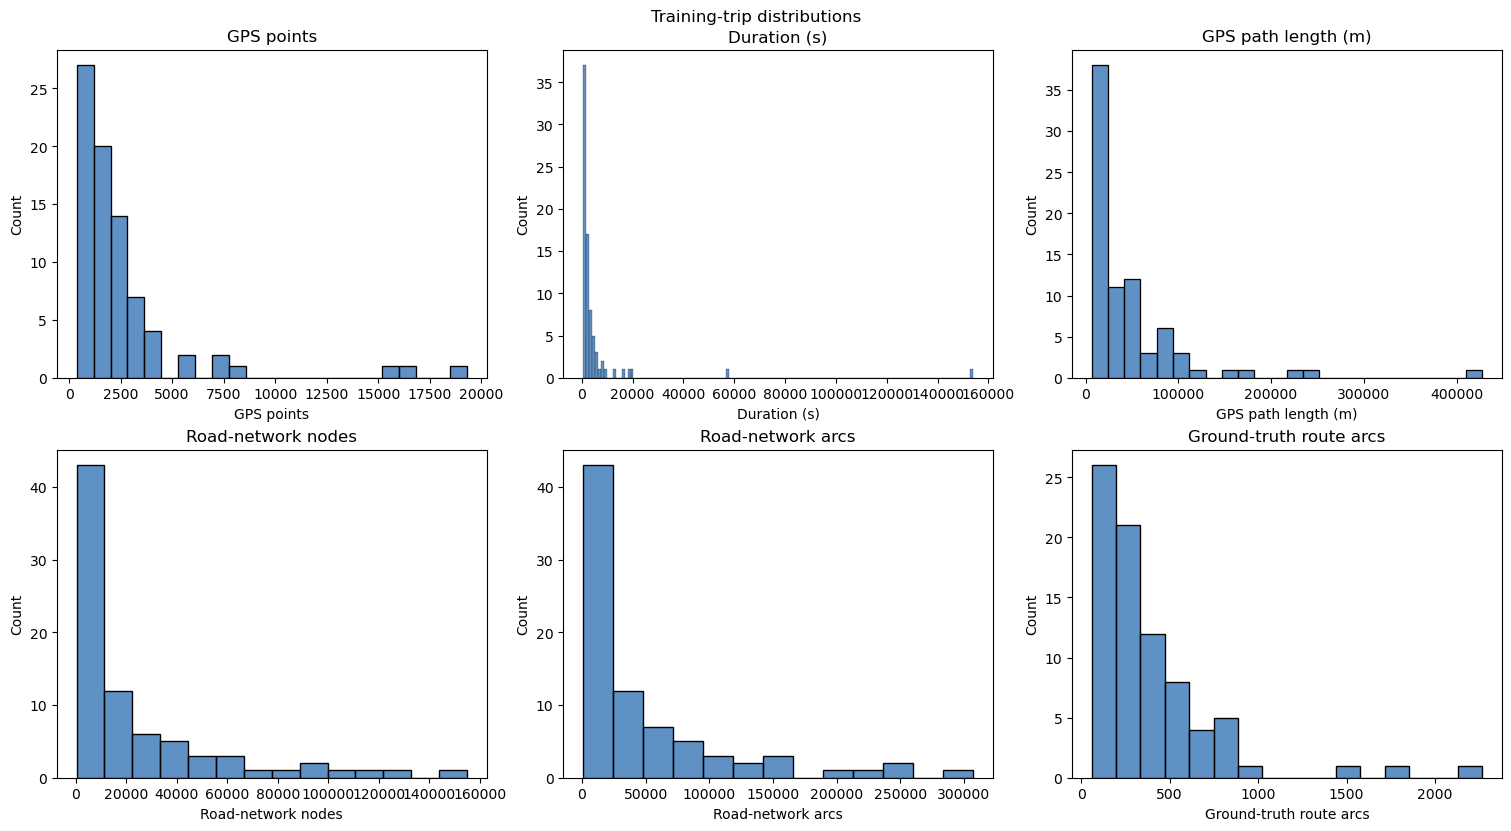

In [6]:
plot_columns = [
    ('gps_points', 'GPS points'),
    ('duration_s', 'Duration (s)'),
    ('gps_path_m', 'GPS path length (m)'),
    ('nodes', 'Road-network nodes'),
    ('arcs', 'Road-network arcs'),
    ('route_arcs', 'Ground-truth route arcs'),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for axis, (column, label) in zip(axes.flat, plot_columns):
    sns.histplot(summary[column], bins='auto', ax=axis, color='#2b6cb0')
    axis.set_title(label)
    axis.set_xlabel(label)
fig.suptitle('Training-trip distributions', y=1.02)
fig.savefig(RESULTS_DIR / 'trip_distributions.png', dpi=180, bbox_inches='tight')
plt.show()

## Representative trip map

The trip with the median GPS-point count is used so the map is not chosen by hand. Grey lines are all directed road arcs, blue points are GPS observations, and orange lines are the labelled route.

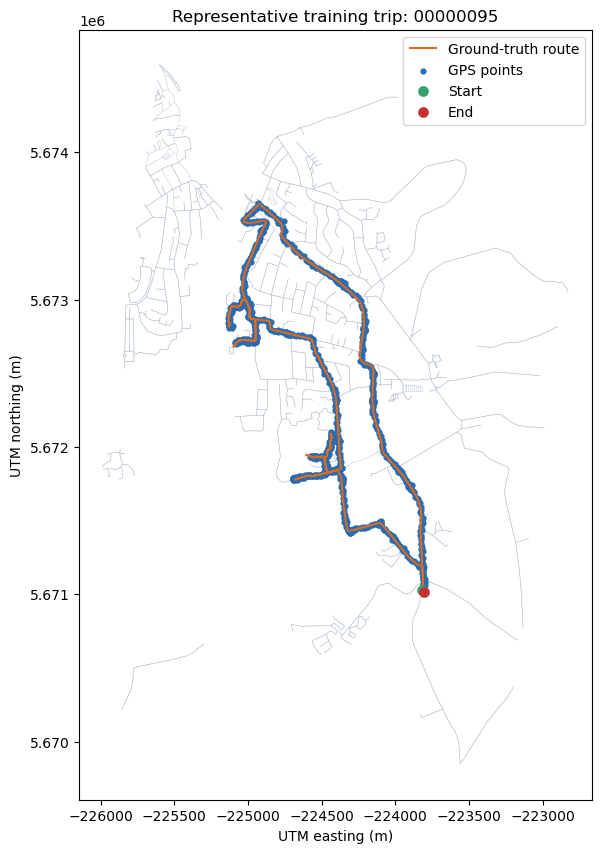

Representative trip: 00000095


In [7]:
representative_id = (
    summary.assign(_distance_from_median=(summary['gps_points'] - summary['gps_points'].median()).abs())
    .sort_values('_distance_from_median')
    .iloc[0]['trip_id']
)
trip = trips[representative_id]
nodes_xy = trip.nodes_xy()
all_segments = nodes_xy[trip.arcs]

fig, axis = plt.subplots(figsize=(10, 10))
axis.add_collection(LineCollection(all_segments, colors='#a0aec0', linewidths=0.35, alpha=0.65))
if trip.route is not None and len(trip.route):
    valid_route = trip.route[(trip.route >= 0) & (trip.route < len(trip.arcs))]
    axis.add_collection(LineCollection(nodes_xy[trip.arcs[valid_route]], colors='#dd6b20', linewidths=1.5, label='Ground-truth route', zorder=4))
track_xy = trip.track_xy()
axis.scatter(track_xy[:, 0], track_xy[:, 1], s=12, color='#2b6cb0', label='GPS points', zorder=3)
axis.scatter(track_xy[0, 0], track_xy[0, 1], s=45, color='#38a169', label='Start', zorder=4)
axis.scatter(track_xy[-1, 0], track_xy[-1, 1], s=45, color='#c53030', label='End', zorder=4)
axis.set_aspect('equal')
axis.set_title(f'Representative training trip: {representative_id}')
axis.set_xlabel('UTM easting (m)')
axis.set_ylabel('UTM northing (m)')
axis.legend(loc='best')
fig.savefig(RESULTS_DIR / 'representative_trip.png', dpi=180, bbox_inches='tight')
plt.show()
print(f'Representative trip: {representative_id}')

## Next steps

Use the generated summaries and map to set candidate-search radius, build point-to-arc labels and features, and create trip-level train/validation splits. Do not use `student_test` or `evaluator` during those steps.